# Qwen3-4B through NVIDIA NIM

**You are here → 03 — Qwen through NIM.**

**Main workflow:** understand a local AI request → optimize Qwen → optimize Nemotron.
**Optional extensions:** model-specific NIM deployment; separate CPU portability branch.

| **Step** | **Notebook** | **Purpose** |
|---|---|---|
| 0. Understand the request | [00 — How a local AI request works](00_local_serving.ipynb) | Follow a question through schema context, model serving and generated SQL, then evaluate the results to establish a quality baseline. |
| 1. Qwen optimization | [01 — Qwen: caching and quantization](01_qwen_optimization.ipynb) | Compare FP16/AWQ W4A16 and prefix caching, with cold and warm requests reported separately. |
| 2. Nemotron optimization | [02 — Nemotron optimization](02_nemotron_optimization.ipynb) | Test schema context, supported prefix caching, concurrent requests, scheduler capacity and output budgets. |
| **→ 3. Qwen NIM (optional) (current)** | [03 — Qwen through NIM](03_qwen_nim.ipynb) | Deploy Qwen in a container, check the plan format, and compare schema context and concurrent requests. |
| 4. Nemotron NIM (optional) | [04 — Nemotron through NIM](04_nemotron_nim.ipynb) | Deploy the hybrid model through NIM and compare schema context and request concurrency. |
| 5. CPU portability (optional) | [05 — Qwen with ExecuTorch](05_edge_portability_executorch.ipynb) | Follow Qwen3-4B conversion and CPU export, then inspect a generated SQL answer and its timing. |
| 6. Compatibility study (optional) | [06 — Nemotron with ExecuTorch](06_nemotron_executorch.ipynb) | Check whether the installed exporter accepts Nemotron and identify what a working port still needs. |

We deploy a vLLM-backed NIM container, check the application response contract, then compare schema context and one, two and four concurrent requests. A NIM profile selects a deployment configuration for the checkpoint and GPU.

The workload is structured clinical-trial questions on synthetic data with no personally identifiable information (PII). We compare response time with executed SQL and reference-result matches.

Configure your GPU environment below, then run the cells in order to collect new measurements. Each experiment saves its results separately. Completed outputs are visible when a live execution has been saved. Full request and result records are linked from each experiment.

Follow [SETUP.md](../SETUP.md) and [the execution guide](../tutorial/RUN_ALL.md) first. The target is **Qwen3-4B**, `Qwen/Qwen3-4B`, on a **Linux NVIDIA GPU**. Model loading and server startup happen before request timing.


## 1. Imports and editable configuration

`MODE` controls execution: **live** collects new inference; **plan** previews commands; **replay** explicitly reads archived results. It overrides an older local JSON mode. CPU validation supplies `LOCAL_AI_LAB_MODE=plan` or `replay` before executing these cells.

Keep machine paths, exact checkpoint revisions and deployment settings in the per-notebook local JSON. Downloads are opt-in. Remove the obsolete `execute` flag; mode is the execution authority.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/clinical_trial_mvp').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import JSON, Markdown, display
from clinical_trial_mvp.tutorial.workflow import Study, read_config
from clinical_trial_mvp.tutorial.teaching import server_example, request_example, response_example, interpret

MODE = "live"  # "plan" previews commands; "replay" displays archived results
MODE = os.environ.get('LOCAL_AI_LAB_MODE', MODE)  # Explicit CPU validation override.
CONFIG = read_config('nim', 'qwen', root=ROOT, mode=MODE)
# Edit CONFIG here or the matching tutorial/config/*.local.json before continuing.
if 'study' in globals():
    study.close()
study = Study('nim', 'qwen', root=ROOT, config=CONFIG, mode=MODE)
results = study.results
print('Effective mode:', study.mode)
print('Model:', 'Qwen/Qwen3-4B')
print('Hardware target: Linux / NVIDIA GPU; actual device checked next')
print('Session:', study.session_id)
print('Current-session measurements:', len(results))


Effective mode: live
Model: Qwen/Qwen3-4B
Hardware target: Linux / NVIDIA GPU; actual device checked next
Session: 20261111T032350-ebdb978c0d
Current-session measurements: 0


## 2. Preflight checks

Check the GPU, selected runtime, checkpoint paths/revisions and port 8000 before loading a model. NIM also checks Docker access, an already available image, GPU access from that image and your selected profile. Missing prerequisites stop with instructions; no package installation or image pull is automatic.


In [3]:
display(JSON(study.preflight()))


<IPython.core.display.JSON object>

## 3. Model preparation and compatibility smoke

Preparation validates local checkpoint identity and precision. It downloads weights only when `download_models=true`. NIM verifies the selected profile against discovery for this deployment.

Qwen's vLLM study requires a successful AWQ SQL smoke before all four variants. Nemotron core needs no AWQ checkpoint: its optional stretch remains separate. NIM smoke tests both serving and SQL execution; a failed required smoke blocks dependent experiments.


In [4]:
print(study.prepare())


Validated local checkpoint/configuration; ready to run.


In [5]:
smoke = study.smoke()
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(smoke)))


Starting smoke | session 20261111T032350-ebdb978c0d
Starting NIM; waiting for readiness. Container: clinical-trial-mvp4-qwen-20261111t032350-ebdb978c0d


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/qwen/smoke | completed | 3/4 | 2/4 | 2.039 / 2.042 | 6.179 / 7.562 | 13.034 / 16.992 | 24.223 | 13.950 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T032350-ebdb978c0d | experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-smoke-38d59afe.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-smoke-38d59afe.json).

## 4. Individual experiments

Keep the NIM deployment fixed while changing full/retrieved schema or client concurrency. TP1/PP1 uses one GPU and one pipeline stage. A runnable profile still needs successful startup and a SQL smoke.

Check response structure as well as HTTP success. Qwen enables schema enforcement by default; Nemotron's setting is explicit in configuration. Compare the request contract before interpreting differences from native vLLM. The owned container stays running between these cells until cleanup.


### baseline

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [6]:
result = study.run('baseline')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'baseline')))


Starting baseline | session 20261111T032350-ebdb978c0d


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/qwen/baseline | completed | 3/4 | 2/4 | 2.042 / 2.048 | 6.189 / 7.760 | 11.994 / 16.915 | 24.169 | 13.950 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T032350-ebdb978c0d | experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-baseline-4ed699e7.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-baseline-4ed699e7.json).

**Prediction:** Establish executable SQL and separate application quality from request speed.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 6.189/7.760 s; aggregate output: 24.169 tok/s.

**Explanation:** Transport timing and application correctness measure different stages.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use this baseline to judge useful completed tasks, not latency alone.

### Inspect the serving call and answer

The experiment above calls the model through the OpenAI-compatible `/v1/chat/completions` API. Inspect the launch command, request, generated plan/SQL and execution checks below. The request is constructed from the experiment prompt, schema profile and generation settings. In Plan, these details preview the configured call. The response shows the generated answer and its reference-result check.

[Request transport](../src/clinical_trial_mvp/serving/client.py) · [plan and SQL execution](../src/clinical_trial_mvp/serving/agent.py)


In [7]:
display(JSON(server_example(study, 'baseline')))
display(JSON(request_example(study, 'baseline')))
display(JSON(response_example(study, 'baseline')))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

### schema retrieved

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [8]:
result = study.run('schema_retrieved')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'schema_retrieved')))


Starting schema_retrieved | session 20261111T032350-ebdb978c0d


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/qwen/schema_retrieved | completed | 4/4 | 3/4 | 0.193 / 0.238 | 2.745 / 3.243 | 9.497 / 10.015 | 40.477 | 13.950 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T032350-ebdb978c0d | experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-schema_retrieved-8ce8d41f.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-schema_retrieved-8ce8d41f.json).

**Prediction:** Less context may reduce input work but can remove definitions required for correct SQL.

**Observation:** Application result match: 3/4; SQL executed: 4/4. Request E2E p50/p95: 2.745/3.243 s; aggregate output: 40.477 tok/s. Baseline application result match: 2/4.

**Explanation:** Context reduction changes the information available to the model, not just compute cost.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Retain needed clinical definitions; accept reduced context only with adequate task quality.

### concurrency 2

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [9]:
result = study.run('concurrency_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_2')))


Starting concurrency_2 | session 20261111T032350-ebdb978c0d


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/qwen/concurrency_2 | completed | 3/4 | 2/4 | 2.090 / 3.254 | 8.605 / 12.915 | 12.053 / 16.982 | 32.553 | 13.950 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T032350-ebdb978c0d | experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-concurrency_2-703b3972.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-concurrency_2-703b3972.json).

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 8.605/12.915 s; aggregate output: 32.553 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### concurrency 4

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [10]:
result = study.run('concurrency_4')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_4')))


Starting concurrency_4 | session 20261111T032350-ebdb978c0d


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/qwen/concurrency_4 | completed | 3/4 | 2/4 | 2.139 / 6.689 | 14.590 / 19.510 | 12.061 / 16.966 | 39.283 | 13.950 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T032350-ebdb978c0d | experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-concurrency_4-d56155fe.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-concurrency_4-d56155fe.json).

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 14.590/19.510 s; aggregate output: 39.283 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

## 5. Current-session comparison and interpretation

Read result matches alongside latency. TTFT measures first generated content; request completion covers generation and transport; application latency includes planning, validation, execution and repair. Missing memory telemetry stays unavailable. Failed rows remain failures.

Compare cold and warm TTFT. Did any reduction carry through to complete-request latency? For concurrency, did throughput improve within your latency budget? For precision or output caps, did the amount or correctness of generated SQL change?


In [11]:
display(Markdown(study.report()))
display(Markdown(study.cache_report()))


**Mode: live · Session: 20261111T032350-ebdb978c0d**

| Configuration/status | SQL | Result match | Semantic review | Prompt tokens | TTFT p50 s | Latency p50/p95 s | tok/s | Peak memory |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/qwen/smoke | 3/4 | 2/4 | Unreviewed; 4 total | 2340 | 2.04 | 6.18/7.56 | 24.22 | 13.95 GiB |
| MVP4/NIM/qwen/baseline | 3/4 | 2/4 | Unreviewed; 4 total | 2340 | 2.04 | 6.19/7.76 | 24.17 | 13.95 GiB |
| MVP4/NIM/qwen/schema_retrieved | 4/4 | 3/4 | Unreviewed; 4 total | 458 | 0.19 | 2.74/3.24 | 40.48 | 13.95 GiB |
| MVP4/NIM/qwen/concurrency_2 | 3/4 | 2/4 | Unreviewed; 4 total | 2340 | 2.09 | 8.61/12.92 | 32.55 | 13.95 GiB |
| MVP4/NIM/qwen/concurrency_4 | 3/4 | 2/4 | Unreviewed; 4 total | 2340 | 2.14 | 14.59/19.51 | 39.28 | 13.95 GiB |

| Experiment | Application E2E p50/p95 s | Request TTFT p95 s |
|---|---|---|
| smoke | 13.034/16.992 | 2.042 |
| baseline | 11.994/16.915 | 2.048 |
| schema_retrieved | 9.497/10.015 | 0.238 |
| concurrency_2 | 12.053/16.982 | 3.254 |
| concurrency_4 | 12.061/16.966 | 6.689 |

Evidence: experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-smoke-38d59afe.json, experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-baseline-4ed699e7.json, experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-schema_retrieved-8ce8d41f.json, experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-concurrency_2-703b3972.json, experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-concurrency_4-d56155fe.json

No controlled prefix-cache phase measurements in these results.

### Plot this session

The figure uses only successful measured rows selected in this session. Missing rows are not filled from another run. Plan produces no measurement figure.


Session figure: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/nim-qwen-20261111T032350-ebdb978c0d-figure-339ee0bf.png


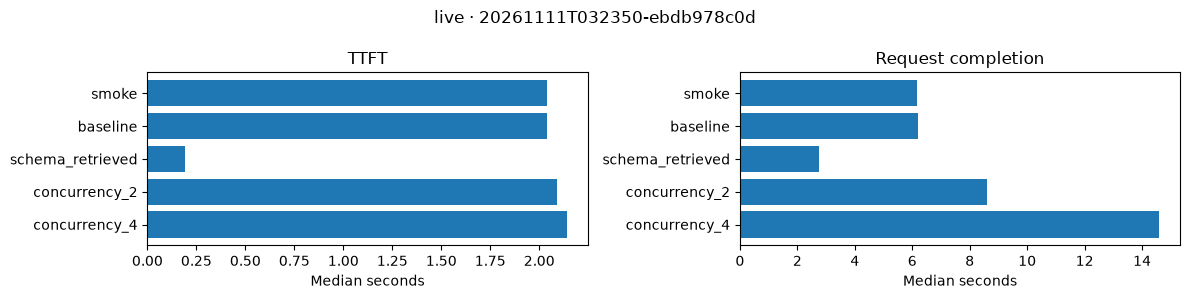

In [12]:
from clinical_trial_mvp.tutorial.session_figures import figure
fig = figure(study)
if fig is not None:
    display(fig)
    import matplotlib.pyplot as plt
    plt.close(fig)
else:
    print('No measured rows available for a figure.')


## 6. Cleanup

Save the notebook to retain genuine Live outputs. Native servers stop after each row. Stop the owned NIM container before switching models or pausing. Cleanup is safe to repeat and does not stop external servers.


In [13]:
print(study.close())


Study servers stopped. Saved records and notebook outputs are retained.
